<h1><center>Практическое задание</h1></center>

1. Возьмите любую Faster RCNN сеть и сравниет её с YOLO при детекции на ваших изображениях
2. Сделайте то же самое, но для видеоряда, оцените разности и точности

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, fasterrcnn_mobilenet_v3_large_320_fpn
from PIL import Image
from torchvision.ops import batched_nms
import numpy as np
from torchvision.utils import draw_bounding_boxes
import matplotlib.pyplot as plt
import cv2
import os
import sys

darknet_path = os.path.abspath("darknet")
if 'darknet' in sys.modules:
    del sys.modules['darknet']

if darknet_path not in sys.path:
    sys.path.insert(0, darknet_path)

import darknet

In [2]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
device

'cuda:0'

In [3]:
dataset_voc =  datasets.VOCDetection(root='D:/MIREA/DPO/Learning/Practic2_8/SimpleNN', image_set='train', download=False)
names = []

for sample in dataset_voc:
    names.extend([obj['name'] for obj in sample[1]['annotation']['object']])

names = sorted(list(set(names)))
print(names)

names_with_backround = ['background'] + names
idx2tar = {idx: name for idx, name in enumerate(names_with_backround)}
tar2idx = {name: idx for idx, name in enumerate(names_with_backround)}


names_coco = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus",
    "train", "truck", "boat", "traffic light", "fire hydrant", "", "stop sign",
    "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "", "backpack", "umbrella", "", "",
    "handbag", "tie", "suitcase", "frisbee", "skis", "snowboard", "sports ball",
    "kite", "baseball bat", "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut",
    "cake", "chair", "couch", "potted plant", "bed", "", "dining table", "", "",
    "toilet", "", "tv", "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator", "", "book", "clock",
    "vase", "scissors", "teddy bear", "hair drier", "toothbrush"
]

names_with_backround_coco = ['background'] + names_coco
idx2tar_coco = {idx: name for idx, name in enumerate(names_with_backround_coco)}
tar2idx_coco = {name: idx for idx, name in enumerate(names_with_backround_coco)}

['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']


In [4]:
def target_transform(targets):
    target = {}
    target['boxes'] = torch.tensor([[
        float(x['bndbox']['xmin']),
        float(x['bndbox']['ymin']),
        float(x['bndbox']['xmax']),
        float(x['bndbox']['ymax'])
    ] for x in targets['annotation']['object']], dtype=torch.float32)
    target['labels'] = torch.tensor([tar2idx[x['name']] for x in targets['annotation']['object']], dtype=torch.int64)
    return target

def collate_fn(batch):
    return tuple(zip(*batch))

def show(images):
    to_pil = transforms.ToPILImage()
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(ncols=len(images), squeeze=False, figsize=(20, 10))
    for idx, image in enumerate(images):
        image = image.detach()
        image = to_pil(image)
        axes[0, idx].imshow(np.asarray(image))
        axes[0, idx].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

def draw_single_image(image, boxes, labels, color):
    colours = [color for _ in boxes]
    show(draw_bounding_boxes(image, boxes, labels, colors=colours, width=6))

def filter_bb(orig_prediction, score_thresh=0.5, iou_thresh=0.5):
    keep_scores = orig_prediction['scores'] > score_thresh

    boxes = orig_prediction['boxes'][keep_scores]
    scores = orig_prediction['scores'][keep_scores]
    labels = orig_prediction['labels'][keep_scores]

    keep_nms = batched_nms(boxes, scores, labels, iou_thresh)

    final_prediction = {
        'boxes': boxes[keep_nms],
        'scores': scores[keep_nms],
        'labels': labels[keep_nms]
    }
    
    return final_prediction

def test_model(model, dataset, list_idx_images=[0, 1, 2, 3, 4], score_thresh=0.5, iou_thresh=0.5):
    model.eval()
    final_images = [torch.tensor(0)] * len(list_idx_images)
    with torch.inference_mode():
        for i, idx in enumerate(list_idx_images):
            img, data = dataset[idx]
            pred = model([img.cpu().float()])[0]
            pred = {k: v.cpu() for k, v in pred.items()}

            pred = filter_bb(pred, score_thresh=score_thresh, iou_thresh=iou_thresh)

            img_uint8 = (img.cpu() * 255).to(torch.uint8)

            true_labels = [idx2tar[label.item()] for label in data['labels']]
            final_images[i] = draw_bounding_boxes(img_uint8, data['boxes'],
                                              true_labels, colors='red',
                                              width=3)
            
            if (len(pred['boxes']) > 0):
                pred_labels = [idx2tar_coco[label.item()] for label in pred['labels']]
                final_images[i] = draw_bounding_boxes(final_images[i], pred['boxes'],
                                                      pred_labels, colors='blue',
                                                      width=2)
                
    return final_images

def test_yolo_darknet(dataset, list_idx_images=[0, 1, 2, 3, 4], score_thresh=0.5, iou_thresh=0.5):
    config_file = 'D:/MIREA/DPO/Learning/Practic2_9/darknet/cfg/yolov4.cfg'
    data_file = 'D:/MIREA/DPO/Learning/Practic2_9/darknet/cfg/coco.data'
    weights_file = 'D:/MIREA/DPO/Learning/Practic2_9/darknet/yolov4.weights'
    darknet_dir = 'D:/MIREA/DPO/Learning/Practic2_9/darknet'

    current_dir = os.getcwd()
    try:
        os.chdir(darknet_dir)
        network, class_names, class_colors = darknet.load_network(
            config_file, data_file, weights_file, batch_size=1
        )
    finally:
        os.chdir(current_dir)

    output_images = []
    for idx in list_idx_images:
        dataset_item = dataset[idx]
        if isinstance(dataset_item, tuple):
            img_tensor = dataset_item[0]
        else:
            img_tensor = dataset_item

        pil_temp = transforms.ToPILImage()(img_tensor)
        temp_image_path = os.path.abspath(f"temp_darknet_in_{idx}.jpg")
        pil_temp.save(temp_image_path)

        darknet_image = darknet.load_image(temp_image_path.encode("utf-8"), 0, 0)
        cv2_image = cv2.imread(temp_image_path)

        detections = darknet.detect_image(
            network, class_names, darknet_image, thresh=score_thresh, nms=iou_thresh
        )
        
        darknet.free_image(darknet_image)
        
        if os.path.exists(temp_image_path):
            os.remove(temp_image_path)
        
        annotated_img_bgr = darknet.draw_boxes(detections, cv2_image, class_colors)
        annotated_img_rgb = cv2.cvtColor(annotated_img_bgr, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(annotated_img_rgb)
        output_images.append(pil_img)
    darknet.free_network_ptr(network)
    return output_images

def vizualize(models, model_names, dataset, list_idx_images=[0, 1, 2, 3, 4], score_thresh=0.5, iou_thresh=0.5):
    len_images = len(list_idx_images)
    final_images = [[None] * len_images for _ in range(2)]

    for i in range(2):
        model_outputs = test_model(models[i], dataset, list_idx_images,
                                   score_thresh, iou_thresh)
        final_images[i] = [transforms.ToPILImage()(img) for img in model_outputs]
    
    final_images.append(test_yolo_darknet(dataset, list_idx_images,
                                        score_thresh, iou_thresh))
    
    fig, axes = plt.subplots(len_images, 3, figsize=(25, 8 * len_images), facecolor='white')

    if len_images == 1:
        axes = np.expand_dims(axes, axis=0)

    for j in range(3):
        for i in range(len_images):
            ax = axes[i][j]
            ax.imshow(final_images[j][i])
            ax.axis('off')
            ax.set_title(f'Image {i} by {model_names[j]} im {list_idx_images[i]}')
    plt.tight_layout()
    plt.show()

In [5]:
dataset = datasets.VOCDetection('D:/MIREA/DPO/Learning/Practic2_8/SimpleNN', image_set='val', download=False,
                                transform=transforms.ToTensor(),
                                target_transform=target_transform)

In [6]:
model_resnet50 = fasterrcnn_resnet50_fpn_v2(weights='DEFAULT')
model_mobilenet = fasterrcnn_mobilenet_v3_large_320_fpn(weights='DEFAULT')


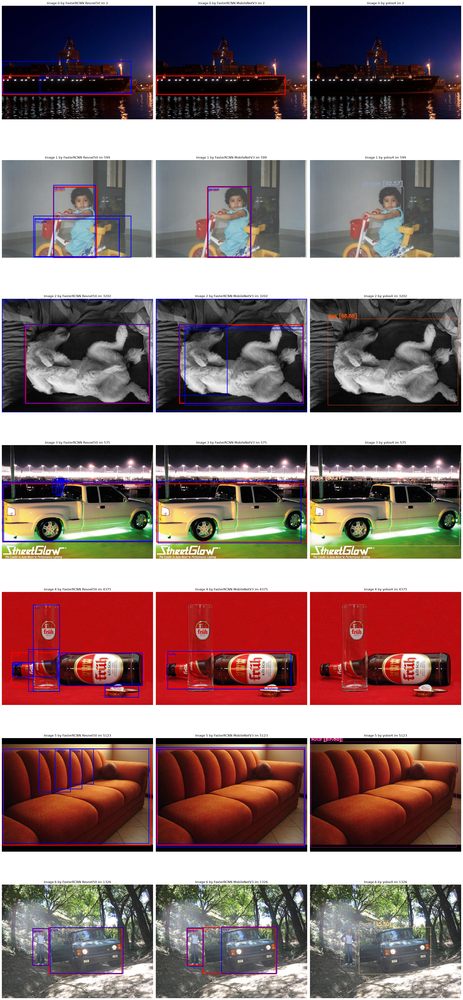

In [7]:
models = [model_resnet50, model_mobilenet]
model_names = ['FasterRCNN Resnet50', 'FasterRCNN MobileNetV3', 'yolov4']

vizualize(models, model_names, dataset, [np.random.randint(0, 5283) for j in range(np.random.randint(5, 10))])

<h2>Результат обработки изображений</h2>

Получилось, что в основном F-RCNN Resnet получше в обработке мелких деталей на изображении. Yolo является средним результатом, позволяя видеть достаточно мелкие детали, в отличие от F-RNN MobileNet. MobileNet видит хуже всех (у него в более чем 2 раза меньше параметров от Resnet), но зато самая быстрая, и почти доходит до yolov4.

In [ ]:
import gc
import numpy as np
import torch
import cv2
from torchvision.utils import draw_bounding_boxes

for i, model in enumerate(models):
    cap = cv2.VideoCapture('D:/MIREA/DPO/Learning/Practic2_9/darknet/data/cats.mp4')

    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(f'D:/MIREA/DPO/Learning/Practic2_9/darknet/data/cats_{i}.mp4', fourcc, fps, (width, height))

    transform = transforms.ToTensor()

    model.to(device)
    model.eval()
    
    with torch.inference_mode():
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_tensor = transform(frame_rgb).to(device)
            prediction = model([frame_tensor])[0]

            prediction = {k: v.cpu() for k, v in prediction.items()}
            pred = filter_bb(prediction, score_thresh=0.8, iou_thresh=0.5)
            
            frame_uint8 = (frame_tensor.cpu() * 255).to(torch.uint8)
            
            if len(pred['boxes']) > 0:
                pred_labels = [idx2tar_coco[label.item()] for label in pred['labels']]
                out_tensor = draw_bounding_boxes(frame_uint8, pred['boxes'], pred_labels, width=3, colors="blue")
            else: 
                out_tensor = frame_uint8

            out_frame_rgb = out_tensor.permute(1, 2, 0).numpy()
            
            out_frame_bgr = cv2.cvtColor(out_frame_rgb, cv2.COLOR_RGB2BGR)

            out.write(out_frame_bgr)
            
    cap.release()
    out.release()
    gc.collect()
    torch.cuda.empty_cache()
